# Step 5: the diffusion scheduler, explained and checked

The real code lives in `ita/diffusion/scheduler.py`. This notebook **imports it**, shows each method,
explains it, and checks it on **real action chunks from the LIBERO dataset** (episode 500,
*"put the bowl on the stove"*).

The scheduler has **no trainable parameters**. It is the fixed math around the network:

- **Training:** take a clean chunk of 16 actions, add a known amount of noise, ask the network to predict that noise.
- **Inference:** start from pure noise and remove it in 10 steps, using the network's noise predictions.

| Part | Method | What it does |
|---|---|---|
| 1 | `__init__` | builds the noise schedule: β_k, α_k, ᾱ_k for k = 0 … 99 |
| 2 | `add_noise` | jumps straight from a clean chunk to noise level k (training) |
| 3 | *(the loss)* | what the network is trained to predict, and why |
| 4 | `ddim_timesteps`, `ddim_step` | one denoising step, and which steps we use |
| 5 | `sample` | the full 10-step loop (inference) |
| 6 | toy experiment | a tiny trained denoiser: why diffusion and not plain regression |

Rule for the graded file: no `diffusers`. Run the cells in order with `Shift + Enter`.

In [1]:
%load_ext autoreload
%autoreload 2

import glob, inspect, json, math, os, time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import Markdown, display

from ita.data.normalization import MinMaxNormalizer
from ita.diffusion.scheduler import NoiseScheduler
from ita.models.transformer import SinusoidalTimestepEmbedding

def show(obj):
    # Print the source code of a method from scheduler.py.
    display(Markdown(f"```python\n{inspect.getsource(obj)}```"))

# Colours used in every plot (fixed order): blue, orange, aqua, yellow, magenta.
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
INK, MUTED = "#2b2b2b", "#8a8a85"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
                     "lines.linewidth": 2, "legend.frameon": False})

torch.manual_seed(0)
print("torch", torch.__version__)

torch 2.15.0+cu132


## 0. A real action chunk from the dataset

We read episode 500 straight from the dataset's parquet files (no images needed) and normalise the actions
to [−1, 1] with the dataset's min/max statistics, exactly as training will do (Step 7).
We pick the 16 actions around the moment the gripper closes on the bowl, so the chunk has an interesting shape.

In [2]:
root = sorted(glob.glob(os.path.expanduser(
    "~/.cache/huggingface/lerobot/hub/datasets--lerobot--libero/snapshots/*")))[-1]
stats = json.load(open(f"{root}/meta/stats.json"))
act_norm = MinMaxNormalizer.from_lerobot_stats(stats, "action")

EP = 500
for f in sorted(glob.glob(f"{root}/data/*/*.parquet")):
    df = pd.read_parquet(f, columns=["episode_index", "frame_index", "action"])
    if EP in set(df.episode_index):
        break
ep = df[df.episode_index == EP].sort_values("frame_index")
actions = torch.tensor(np.stack(ep.action.values), dtype=torch.float32)   # (T, 7), raw units

close = int((actions[:, 6] > 0).nonzero()[0])            # first frame where the gripper closes
start = max(0, close - 8)
chunk_raw = actions[start:start + 16]                      # (16, 7)
x0 = act_norm.normalize(chunk_raw)[None]                   # (1, 16, 7) in [-1, 1]

print(f"episode {EP}: {len(actions)} frames, gripper closes at frame {close}, chunk = frames {start}-{start + 15}")
print("normalised range:", round(x0.min().item(), 3), "to", round(x0.max().item(), 3))
NAMES = ["dx", "dy", "dz", "droll", "dpitch", "dyaw", "gripper"]
print(pd.DataFrame(x0[0].numpy().round(2), columns=NAMES).head(10))

episode 500: 92 frames, gripper closes at frame 34, chunk = frames 26-41
normalised range: -1.0 to 1.0
     dx    dy    dz  droll  dpitch  dyaw  gripper
0 -0.53 -0.13 -1.00  -0.16    0.00 -0.22     -1.0
1 -0.57 -0.16 -1.00  -0.16    0.00 -0.21     -1.0
2 -0.56 -0.15 -1.00  -0.16    0.00 -0.20     -1.0
3 -0.55 -0.11 -0.97  -0.16    0.00 -0.19     -1.0
4 -0.54 -0.08 -0.91  -0.16    0.00 -0.17     -1.0
5 -0.53 -0.07 -0.84  -0.16    0.00 -0.17     -1.0
6 -0.49 -0.07 -0.74  -0.16    0.00 -0.15     -1.0
7 -0.43 -0.07 -0.61  -0.16    0.04 -0.15     -1.0
8 -0.30 -0.03 -0.40  -0.18    0.10 -0.13      1.0
9 -0.21  0.00 -0.23  -0.22    0.14 -0.09      1.0


---
# Part 1: The noise schedule

## 1.1 The idea

Diffusion destroys a clean chunk $x_0$ **a little at a time** over $K = 100$ steps. At step $k$ we shrink the
signal slightly and add a little Gaussian noise of variance $\beta_k$:

$$x_k = \sqrt{1-\beta_k}\; x_{k-1} + \sqrt{\beta_k}\; z, \qquad z \sim \mathcal N(0, I)$$

With $\alpha_k = 1 - \beta_k$ and the running product $\bar\alpha_k = \prod_{i \le k} \alpha_i$, the whole
chain collapses into one formula (Part 2):

$$x_k = \sqrt{\bar\alpha_k}\; x_0 + \sqrt{1-\bar\alpha_k}\;\varepsilon$$

So $\bar\alpha_k$ (`alphas_cumprod`) is the single number that says **how much of the clean chunk is left at step k**:
≈ 1 at k = 0 (clean), ≈ 0 at k = 99 (pure noise). The *schedule* is the choice of the β's.

## 1.2 The code

In [3]:
import ita.diffusion.scheduler as sched_module
show(sched_module._squaredcos_betas)
show(sched_module._linear_betas)
show(NoiseScheduler.__init__)

```python
def _squaredcos_betas(K: int, s: float = 0.008, max_beta: float = 0.999) -> torch.Tensor:
    t = torch.arange(K + 1, dtype=torch.float64) / K                     # 0, 1/K, ..., 1
    f = torch.cos((t + s) / (1 + s) * math.pi / 2) ** 2                    # f(0) .. f(K), f(t) ~ abar
    betas = 1 - f[1:] / f[:-1]                                             # (K,)
    return betas.clamp(max=max_beta)
```

```python
def _linear_betas(K: int) -> torch.Tensor:
    scale = 1000 / K                                                       # keeps abar_K close to 0 for small K
    return torch.linspace(scale * 1e-4, scale * 0.02, K, dtype=torch.float64)
```

```python
    def __init__(self, num_train_steps: int = 100, schedule: str = "squaredcos"):
        self.num_train_steps = K = num_train_steps
        if schedule == "squaredcos":
            betas = _squaredcos_betas(K)
        elif schedule == "linear":
            betas = _linear_betas(K)
        else:
            raise ValueError(f"unknown schedule {schedule!r} (use 'squaredcos' or 'linear')")

        # Computed in float64 for an accurate cumulative product, stored as float32.
        alphas = 1 - betas
        self.betas = betas.float()                                         # (K,)
        self.alphas = alphas.float()                                       # (K,)
        self.alphas_cumprod = torch.cumprod(alphas, dim=0).float()         # (K,), abar_k
```

**Cosine ("squaredcos") schedule** (Nichol & Dhariwal 2021). Instead of choosing the β's directly, it chooses
the curve $\bar\alpha$ we want, $f(t) = \cos^2\!\big(\tfrac{t/K + s}{1+s}\cdot\tfrac{\pi}{2}\big)$, and then reads off each
β as the ratio between two neighbours: $\beta_k = 1 - f(k+1)/f(k)$. The small offset $s = 0.008$ keeps $\beta_0$ from being
almost zero. β is capped at 0.999 so that $\alpha_k$ never reaches 0.

The cumulative product is done in float64 (100 multiplications lose precision in float32), then stored as float32.

## 1.3 Look at the numbers

In [4]:
cos_s = NoiseScheduler(100, "squaredcos")
lin_s = NoiseScheduler(100, "linear")
print("shapes:", cos_s.betas.shape, cos_s.alphas.shape, cos_s.alphas_cumprod.shape)
for k in [0, 1, 10, 25, 50, 75, 90, 98, 99]:
    ab = cos_s.alphas_cumprod[k].item()
    print(f"k={k:3d}  beta={cos_s.betas[k].item():.5f}  abar={ab:.5f}  "
          f"signal sqrt(abar)={math.sqrt(ab):.3f}  noise sqrt(1-abar)={math.sqrt(1 - ab):.3f}")

shapes: torch.Size([100]) torch.Size([100]) torch.Size([100])
k=  0  beta=0.00063  abar=0.99937  signal sqrt(abar)=1.000  noise sqrt(1-abar)=0.025
k=  1  beta=0.00112  abar=0.99825  signal sqrt(abar)=0.999  noise sqrt(1-abar)=0.042
k= 10  beta=0.00553  abar=0.96672  signal sqrt(abar)=0.983  noise sqrt(1-abar)=0.182
k= 25  beta=0.01345  abar=0.83562  signal sqrt(abar)=0.914  noise sqrt(1-abar)=0.405
k= 50  beta=0.03155  abar=0.47826  signal sqrt(abar)=0.692  noise sqrt(1-abar)=0.722
k= 75  beta=0.07470  abar=0.13349  signal sqrt(abar)=0.365  noise sqrt(1-abar)=0.931
k= 90  beta=0.18875  abar=0.01954  signal sqrt(abar)=0.140  noise sqrt(1-abar)=0.990
k= 98  beta=0.74994  abar=0.00024  signal sqrt(abar)=0.016  noise sqrt(1-abar)=1.000
k= 99  beta=0.99900  abar=0.00000  signal sqrt(abar)=0.000  noise sqrt(1-abar)=1.000


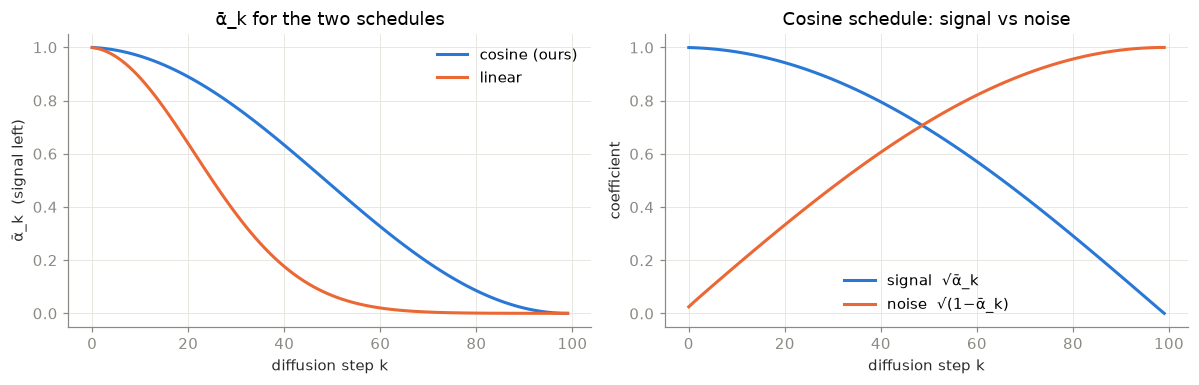

cosine : steps with abar > 0.9:  19 | 0.1 < abar < 0.9:  60 | abar < 0.1:  21
linear : steps with abar > 0.9:  10 | 0.1 < abar < 0.9:  37 | abar < 0.1:  53


In [5]:
k = np.arange(100)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
ax.plot(k, cos_s.alphas_cumprod, color=BLUE, label="cosine (ours)")
ax.plot(k, lin_s.alphas_cumprod, color=ORANGE, label="linear")
ax.set(xlabel="diffusion step k", ylabel="ᾱ_k  (signal left)", title="ᾱ_k for the two schedules")
ax.legend()

ax = axes[1]
ab = cos_s.alphas_cumprod
ax.plot(k, ab.sqrt(), color=BLUE, label="signal  √ᾱ_k")
ax.plot(k, (1 - ab).sqrt(), color=ORANGE, label="noise  √(1−ᾱ_k)")
ax.set(xlabel="diffusion step k", ylabel="coefficient", title="Cosine schedule: signal vs noise")
ax.legend()
plt.tight_layout(); plt.show()

for name, s in [("cosine", cos_s), ("linear", lin_s)]:
    a = s.alphas_cumprod
    print(f"{name:7s}: steps with abar > 0.9: {(a > 0.9).sum().item():3d} | "
          f"0.1 < abar < 0.9: {((a > 0.1) & (a < 0.9)).sum().item():3d} | abar < 0.1: {(a < 0.1).sum().item():3d}")

**Reading the plot.** The linear schedule destroys the signal quickly: after about a third of the steps almost
nothing is left, so many training steps are spent on inputs that are already pure noise. The cosine curve
declines smoothly and spends many more steps in the middle range (0.1 < ᾱ < 0.9), where the denoising problem is
actually informative. That is why Diffusion Policy and our config use `schedule: squaredcos`.

The official test checks: shape (K,), every ᾱ strictly between 0 and 1, strictly decreasing.

In [6]:
a = cos_s.alphas_cumprod
print("shape (K,):        ", a.shape == (100,))
print("inside (0, 1):     ", bool(torch.all(a > 0) and torch.all(a < 1)))
print("strictly decreasing:", bool(torch.all(a[1:] < a[:-1])))

shape (K,):         True
inside (0, 1):      True
strictly decreasing: True


## 1.4 Self-check

1. What does $\bar\alpha_k$ measure, in one sentence?
2. Why must every β be strictly positive, and why is β capped at 0.999?
3. Why does the cosine schedule usually train better than the linear one at K = 100?

<details>
<summary>Answers</summary>

1. The fraction of the clean chunk's variance still present at step k (the signal weight is √ᾱ_k).
2. β > 0 makes ᾱ strictly decreasing (each step adds noise). If β were 1, α = 0 and ᾱ would become exactly 0
   for all later steps, and the DDIM formula divides by √ᾱ_t. The cap keeps it tiny but positive.
3. It spends more steps at intermediate noise levels, where the network learns the most, instead of wasting
   steps on inputs that are already pure noise.
</details>

---
# Part 2: `add_noise`, the forward process (training)

## 2.1 The code

In [7]:
show(NoiseScheduler._abar)
show(NoiseScheduler.add_noise)

```python
    def _abar(self, t: torch.Tensor, device: torch.device) -> torch.Tensor:
        """abar for a batch of integer steps, on the right device."""
        return self.alphas_cumprod.to(device)[t.to(device).long()]
```

```python
    def add_noise(self, x0: torch.Tensor, noise: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        """x0, noise: (B, H, A); t: (B,) long -> x_t (B, H, A)."""
        ab = self._abar(t, x0.device).view(-1, *([1] * (x0.dim() - 1)))  # (B, 1, 1) broadcasts over H, A
        return ab.sqrt() * x0 + (1 - ab).sqrt() * noise
```

During training, each chunk in the batch gets its **own random step** k. `ᾱ` is looked up for each one and
reshaped to (B, 1, 1) so it multiplies all 16 × 7 numbers of that chunk. The table is moved to the data's
device, so this works on the GPU too.

## 2.2 Check: the shortcut equals 100 small steps

The shortcut formula claims that adding noise step by step k times gives the same distribution as one jump.
We check it with 20 000 noisy copies of our real chunk: mean and standard deviation must match
$\sqrt{\bar\alpha_k}\,x_0$ and $\sqrt{1-\bar\alpha_k}$.

In [8]:
K_CHECK, N = 50, 20_000
x = x0.expand(N, -1, -1).clone()
for i in range(K_CHECK + 1):                                   # apply steps 0 .. K_CHECK one by one
    x = cos_s.alphas[i].sqrt() * x + cos_s.betas[i].sqrt() * torch.randn_like(x)

ab = cos_s.alphas_cumprod[K_CHECK]
jump = cos_s.add_noise(x0.expand(N, -1, -1), torch.randn(N, 16, 7), torch.full((N,), K_CHECK))
print(f"k = {K_CHECK}:  sqrt(abar) = {ab.sqrt():.4f},  sqrt(1 - abar) = {(1 - ab).sqrt():.4f}")
print("max |mean(step by step) - sqrt(abar) x0| :", (x.mean(0) - ab.sqrt() * x0[0]).abs().max().item())
print("std step by step:", round(x.std(0).mean().item(), 4), "| std one jump:", round(jump.std(0).mean().item(), 4))

k = 50:  sqrt(abar) = 0.6916,  sqrt(1 - abar) = 0.7223
max |mean(step by step) - sqrt(abar) x0| : 0.01311006024479866
std step by step: 0.7219 | std one jump: 0.7223


Both agree up to sampling noise (≈ 0.01 for 20 000 samples). This is why training is cheap: we never
simulate the chain, we jump to any k directly.

## 2.3 See it: a real chunk at different noise levels

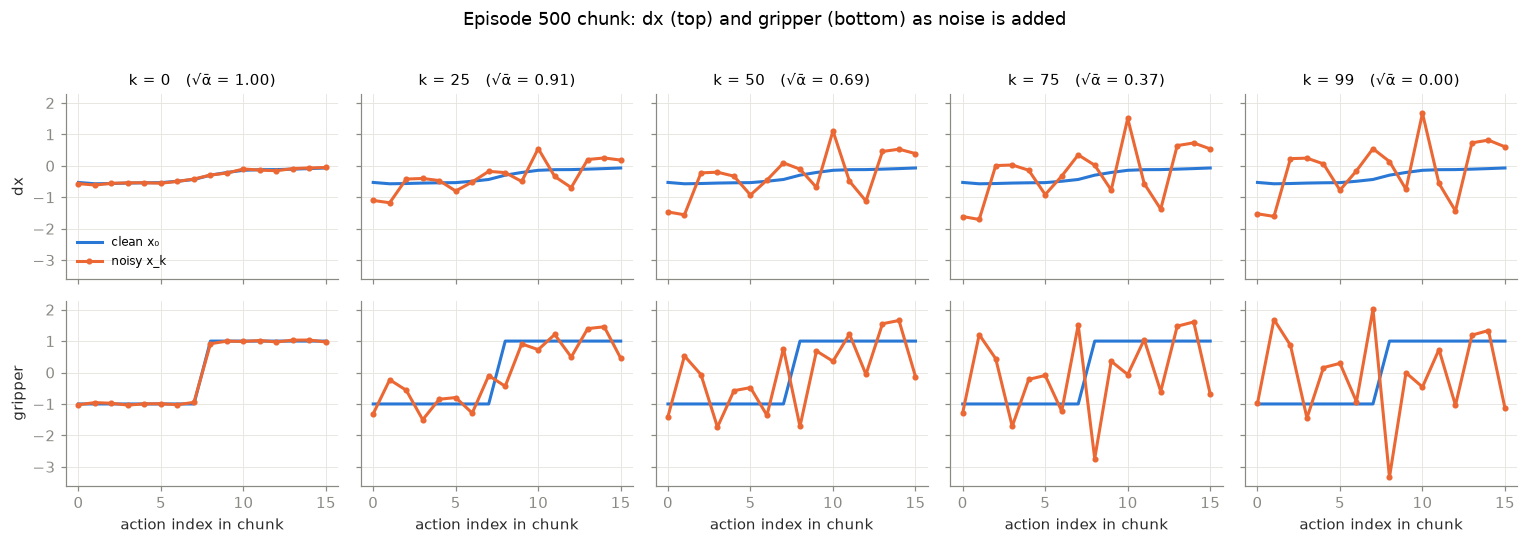

In [9]:
torch.manual_seed(1)
eps = torch.randn_like(x0)
levels = [0, 25, 50, 75, 99]
fig, axes = plt.subplots(2, len(levels), figsize=(14, 4.8), sharex=True, sharey=True)
h = np.arange(16)
for j, kk in enumerate(levels):
    xk = cos_s.add_noise(x0, eps, torch.tensor([kk]))[0]
    for row, dim in enumerate([0, 6]):                     # dx and gripper
        ax = axes[row, j]
        ax.plot(h, x0[0, :, dim], color=BLUE, label="clean x₀")
        ax.plot(h, xk[:, dim], color=ORANGE, marker="o", markersize=3, label="noisy x_k")
        if row == 0:
            ax.set_title(f"k = {kk}   (√ᾱ = {cos_s.alphas_cumprod[kk].sqrt():.2f})", fontsize=10)
        if j == 0:
            ax.set_ylabel(NAMES[dim])
        if row == 1:
            ax.set_xlabel("action index in chunk")
axes[0, 0].legend(loc="lower left", fontsize=8)
plt.suptitle("Episode 500 chunk: dx (top) and gripper (bottom) as noise is added", y=1.02)
plt.tight_layout(); plt.show()

In [10]:
# At k = 99 nothing of the chunk is left: x_99 should look like N(0, 1) whatever x0 was.
x99 = cos_s.add_noise(x0.expand(5000, -1, -1), torch.randn(5000, 16, 7), torch.full((5000,), 99))
print("k=99: mean", round(x99.mean().item(), 3), " std", round(x99.std().item(), 3),
      " correlation with x0:", round(np.corrcoef(x99.mean(0).flatten(), x0.flatten())[0, 1], 3))

k=99: mean -0.001  std 1.001  correlation with x0: -0.046


At k = 25 the shape of the chunk (the gripper step from −1 to +1) is still visible; at k = 75 it is mostly
hidden; at k = 99 it is gone (mean 0, std 1). The network will see all of these levels during training.

The official test checks `add_noise` against the formula to 1e-5:

In [11]:
xb, nb_ = torch.randn(3, 16, 7), torch.randn(3, 16, 7)
t = torch.tensor([0, 50, 99])
abt = cos_s.alphas_cumprod[t].view(-1, 1, 1)
print("matches formula:", torch.allclose(cos_s.add_noise(xb, nb_, t), abt.sqrt() * xb + (1 - abt).sqrt() * nb_, atol=1e-5))

matches formula: True


## 2.4 Self-check

1. Why is `t` a vector of shape (B,) and not one number for the whole batch?
2. What are the shapes of `ab` before and after `.view(-1, 1, 1)` for a batch of 256 chunks?
3. If $x_0$ were *not* normalised (dx up to ±0.94 but gripper exactly ±1, state in metres…), what would go wrong at k = 99?

<details>
<summary>Answers</summary>

1. Each chunk gets its own random noise level, so a single batch trains the network on many levels at once.
2. (256,) → (256, 1, 1), which broadcasts over the 16 actions and 7 dimensions.
3. Nothing at k = 99 itself, but the end points would not match: sampling starts from N(0, 1), and the clean data
   should have a comparable scale. With very different scales per dimension, the noise would swamp small
   dimensions early and barely touch large ones. Normalising every dimension to [−1, 1] makes one schedule fit
   all dimensions, and also makes the clip to [−1, 1] in DDIM valid.
</details>

---
# Part 3: What the network learns (ε-prediction)

The network never sees the clean chunk directly. During training (Step 8):

```python
k     = random integers in [0, 100)                  # (B,)
eps   = torch.randn_like(x0)                          # (B, 16, 7)
x_k   = scheduler.add_noise(x0, eps, k)
eps_pred = network(x_k, k, observation)              # the encoder–decoder Transformer
loss  = mse(eps_pred, eps)
```

**Why predict the noise ε and not x₀?** The two are equivalent: from $x_k$ and ε you can get $x_0$ exactly,

$$x_0 = \frac{x_k - \sqrt{1-\bar\alpha_k}\,\varepsilon}{\sqrt{\bar\alpha_k}}$$

but ε always has the same scale (std 1) at every k, which makes the regression target well-behaved.
This is the choice of DDPM (Ho et al. 2020) and Diffusion Policy (`prediction: epsilon` in our config).

Check the inversion, and the two "baseline" losses that a useless network would get:

In [12]:
torch.manual_seed(2)
B = 4096
xb = x0.expand(B, -1, -1)
kb = torch.randint(0, 100, (B,))
eps = torch.randn(B, 16, 7)
xk = cos_s.add_noise(xb, eps, kb)

abk = cos_s.alphas_cumprod[kb].view(-1, 1, 1)
x0_back = (xk - (1 - abk).sqrt() * eps) / abk.sqrt()
print("inversion error with the true eps:", (x0_back - xb).abs().max().item())

mse = lambda a, b: ((a - b) ** 2).mean().item()
print("loss if the network always outputs 0        :", round(mse(torch.zeros_like(eps), eps), 3))
print("loss if it outputs x_k itself (copies input):", round(mse(xk, eps), 3))
print("loss of a perfect network                   :", mse(eps, eps))

inversion error with the true eps: 0.00023762881755828857
loss if the network always outputs 0        : 0.998
loss if it outputs x_k itself (copies input): 0.327
loss of a perfect network                   : 0.0


So in Step 9 the training loss starts near **1.0** (a network that knows nothing) and should fall well
below it. Copying the input is a good guess only at high k (where $x_k \approx \varepsilon$), which is why the
network must be told k: the timestep embedding from Step 4.

## 3.1 Self-check

1. What is the training loss of a network that outputs zeros, and why exactly that number?
2. Why does the network need the step k as an input?

<details>
<summary>Answers</summary>

1. ≈ 1.0, because ε ~ N(0, 1) has variance 1 and the MSE of predicting 0 is E[ε²] = 1.
2. The same noisy input could come from "a clean chunk with a little noise" or "almost pure noise". How much of
   $x_k$ is noise depends on k, so without k the network cannot know how much to remove.
</details>

---
# Part 4: One DDIM step, and which steps we use

## 4.1 The DDIM update

DDIM (Song et al. 2021) removes noise **deterministically** (η = 0). From step t to an earlier step t_prev:

1. **Guess the clean chunk** with the inversion formula from Part 3, using the predicted noise:
   $\hat x_0 = (x_t - \sqrt{1-\bar\alpha_t}\,\hat\varepsilon)/\sqrt{\bar\alpha_t}$, then clip to [−1, 1].
2. **Re-noise the guess** to the lower noise level of t_prev, reusing the same noise direction:
   $x_{t_{prev}} = \sqrt{\bar\alpha_{t_{prev}}}\,\hat x_0 + \sqrt{1-\bar\alpha_{t_{prev}}}\,\hat\varepsilon$.

At the last step t_prev = −1 and we use $\bar\alpha = 1$, so the output is exactly $\hat x_0$.
Because DDIM can jump over many steps at once, we can train with K = 100 but sample with only 10 network calls.

## 4.2 The code

In [13]:
show(NoiseScheduler.ddim_step)

```python
    def ddim_step(self, eps_pred: torch.Tensor, t: int, t_prev: int, x_t: torch.Tensor) -> torch.Tensor:
        """One deterministic DDIM update (eta = 0) from step t to step t_prev (t_prev < 0 = final step)."""
        ab_t = self.alphas_cumprod[t].item()
        ab_prev = self.alphas_cumprod[t_prev].item() if t_prev >= 0 else 1.0

        # 1) Guess the clean chunk from the noisy one and the predicted noise. Actions live in [-1, 1].
        x0_pred = (x_t - math.sqrt(1 - ab_t) * eps_pred) / math.sqrt(ab_t)
        x0_pred = x0_pred.clamp(-1, 1)

        # 2) Re-noise that guess to the (smaller) noise level of t_prev, reusing the same noise direction.
        return math.sqrt(ab_prev) * x0_pred + math.sqrt(1 - ab_prev) * eps_pred
```

Check one step by hand against `ddim_step`. Here we cheat and give it the **true** noise (an "oracle"):

In [14]:
torch.manual_seed(3)
eps = torch.randn_like(x0)
t, t_prev = 55, 44
x_t = cos_s.add_noise(x0, eps, torch.tensor([t]))

ab_t, ab_p = cos_s.alphas_cumprod[t], cos_s.alphas_cumprod[t_prev]
x0_hat = ((x_t - (1 - ab_t).sqrt() * eps) / ab_t.sqrt()).clamp(-1, 1)
by_hand = ab_p.sqrt() * x0_hat + (1 - ab_p).sqrt() * eps

print("ddim_step == by hand:", torch.allclose(cos_s.ddim_step(eps, t, t_prev, x_t), by_hand, atol=1e-6))
print("x0_hat == true x0   :", torch.allclose(x0_hat, x0, atol=1e-5))
print("lands exactly on x_44:", torch.allclose(by_hand, cos_s.add_noise(x0, eps, torch.tensor([t_prev])), atol=1e-5))

ddim_step == by hand: True
x0_hat == true x0   : True
lands exactly on x_44: True


With the true noise, one step already lands **exactly** on the noisy chunk at step 44, and $\hat x_0$ is already
the clean chunk. A real network's $\hat\varepsilon$ is imperfect, especially at high noise, so it needs several
steps: each step makes a rough guess, re-noises it a bit less, and lets the network correct it. Part 6 shows this
with a trained model.

## 4.3 Which steps? `ddim_timesteps`

In [15]:
show(NoiseScheduler.ddim_timesteps)
for n in [1, 2, 5, 10]:
    print(f"n={n:2d}:", cos_s.ddim_timesteps(n))

```python
    def ddim_timesteps(self, num_inference_steps: int) -> list[int]:
        """Evenly spaced from K-1 down to 0, e.g. K=100, n=10 -> [99, 88, 77, ..., 11, 0].

        Starting at K-1 (abar ~ 0) matches the pure noise we start from. The "leading" spacing
        [90, 80, ..., 0] starts at a step that still contains ~14% signal. On a trained toy model
        this spacing is better for 3-10 steps; with 1-2 steps the epsilon -> x0 inversion at
        k = K-1 is ill-conditioned (divides by sqrt(abar) ~ 5e-4), so use n >= 3.
        See notebooks/step5_scheduler.ipynb, Parts 4.3 and 6.2.
        """
        K, n = self.num_train_steps, num_inference_steps
        assert 1 <= n <= K, f"num_inference_steps must be in [1, {K}]"
        if n == 1:
            return [K - 1]
        return [round((K - 1) * (n - 1 - i) / (n - 1)) for i in range(n)]
```

n= 1: [99]
n= 2: [99, 0]
n= 5: [99, 74, 50, 25, 0]
n=10: [99, 88, 77, 66, 55, 44, 33, 22, 11, 0]


**A design choice we made.** Sampling always starts from pure noise N(0, I). The first step should therefore be
a step whose true noisy input *is* pure noise, i.e. k = 99 (ᾱ ≈ 2·10⁻⁷).

The common "leading" spacing `[90, 80, …, 0]` starts at k = 90, where a real noisy chunk still contains
14 % signal, and with n = 1 it would run a single step at k = 0, telling the network "this is almost clean" when it is
pure noise. Our spacing goes evenly from 99 down to 0. Both satisfy the official test (10 steps, descending, ends at 0).
Part 6 measures the difference.

In [16]:
for name, ts in [("ours (99 -> 0)", cos_s.ddim_timesteps(10)), ("leading (90 -> 0)", list(range(90, -1, -10)))]:
    print(f"{name:18s} first step k={ts[0]:2d}: signal in a true x_k = sqrt(abar) = {cos_s.alphas_cumprod[ts[0]].sqrt():.4f}")

ours (99 -> 0)     first step k=99: signal in a true x_k = sqrt(abar) = 0.0005
leading (90 -> 0)  first step k=90: signal in a true x_k = sqrt(abar) = 0.1398


## 4.4 Self-check

1. Why do we clip $\hat x_0$ to [−1, 1]?
2. What does the last DDIM step return, and why?
3. Why can DDIM use 10 steps when the model was trained with 100?

<details>
<summary>Answers</summary>

1. All normalised actions lie in [−1, 1]. Early guesses (from very noisy inputs) can overshoot; clipping removes
   impossible values before they are re-noised, which stabilises sampling.
2. $\hat x_0$ itself: with t_prev < 0 we set ᾱ_prev = 1, so the noise term vanishes.
3. The network was trained at every k, and DDIM's update only needs ᾱ at the two steps it jumps between, so it
   can skip the steps in between. Fewer steps = fewer network calls = faster control (10 calls per chunk).
</details>

---
# Part 5: `sample`, the full inference loop

## 5.1 The code

In [17]:
show(NoiseScheduler.sample)

```python
    @torch.no_grad()
    def sample(self, eps_fn: Callable[[torch.Tensor, torch.Tensor], torch.Tensor], shape: tuple,
               num_inference_steps: int = 10, device: str | torch.device = "cpu",
               generator: torch.Generator | None = None) -> torch.Tensor:
        """Start from x ~ N(0, I) of `shape`, call eps_fn(x_t, t_batch) at each DDIM step, return x_0."""
        x = torch.randn(shape, generator=generator, device=device)
        timesteps = self.ddim_timesteps(num_inference_steps)
        for i, t in enumerate(timesteps):
            t_prev = timesteps[i + 1] if i + 1 < len(timesteps) else -1
            t_batch = torch.full((shape[0],), t, dtype=torch.long, device=device)
            eps = eps_fn(x, t_batch)
            x = self.ddim_step(eps, t, t_prev, x)
        return x
```

`eps_fn(x_t, t_batch)` is any function that predicts the noise. In Step 8 it will be the decoder, with the encoder's
memory fixed for the whole loop (the observation is encoded once). The official test uses an **oracle** that
knows the true $x_0$ and returns exactly the noise contained in $x_t$; then DDIM must return $x_0$.

## 5.2 Oracle check on the real chunk

In [18]:
def oracle_for(target):
    def eps_fn(x_t, t):
        ab = cos_s.alphas_cumprod[t].view(-1, 1, 1)
        return (x_t - ab.sqrt() * target) / (1 - ab).sqrt()
    return eps_fn

trajectory = []
def recording_oracle(x_t, t):
    trajectory.append((t[0].item(), x_t[0].clone()))
    return oracle_for(x0)(x_t, t)

g = torch.Generator().manual_seed(0)
out = cos_s.sample(recording_oracle, x0.shape, num_inference_steps=10, generator=g)
print("max |sample - x0| (normalised):", (out - x0).abs().max().item())
print("max |sample - x0| (raw units)  :", (act_norm.unnormalize(out[0]) - chunk_raw).abs().max().item())
print("gripper values back in raw units:", act_norm.unnormalize(out[0])[:, 6].round().tolist())

max |sample - x0| (normalised): 9.313225746154785e-10
max |sample - x0| (raw units)  : 5.960464477539063e-08
gripper values back in raw units: [-1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


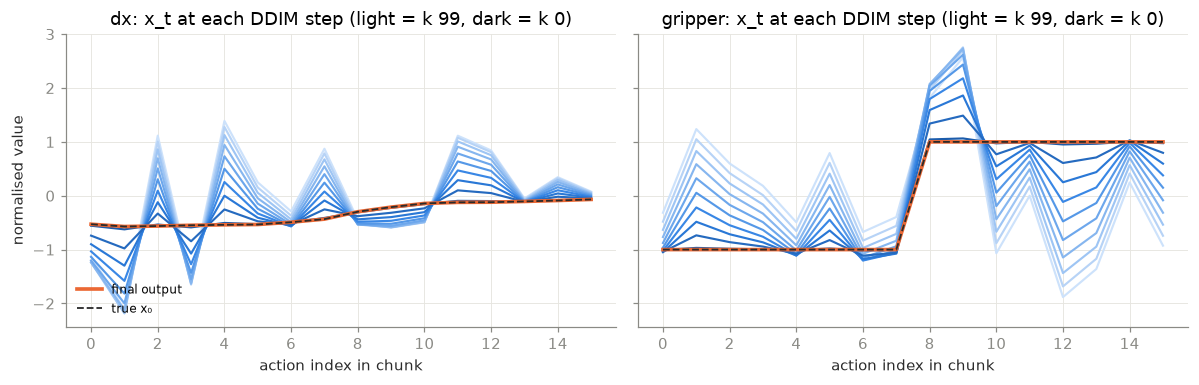

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
ramp = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7", "#3987e5", "#2a78d6", "#256abf", "#1c5cab"]
for ax, dim in zip(axes, [0, 6]):
    for (tt, xt), c in zip(trajectory, ramp):
        ax.plot(h, xt[:, dim], color=c, linewidth=1.4)
    ax.plot(h, out[0, :, dim], color=ORANGE, linewidth=2.4, label="final output")
    ax.plot(h, x0[0, :, dim], color=INK, linestyle="--", linewidth=1.2, label="true x₀")
    ax.set(title=f"{NAMES[dim]}: x_t at each DDIM step (light = k 99, dark = k 0)", xlabel="action index in chunk")
axes[0].set_ylabel("normalised value"); axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

The curves go from pure noise (light) to the clean chunk (dark), and the final output sits exactly on the
true chunk. After un-normalising, the gripper values are exactly −1 / +1 again, ready for `env.step`.

The official test, plus a timing check (with the real network each call costs one decoder pass, so 10 vs 100 steps matters):

In [20]:
torch.manual_seed(0)
xt_ = torch.rand(2, 16, 7) * 2 - 1
print("official oracle test passes:",
      torch.allclose(cos_s.sample(oracle_for(xt_), xt_.shape, num_inference_steps=10), xt_, atol=1e-3))

calls = []
counter = lambda x_t, t: (calls.append(1), torch.zeros_like(x_t))[1]
for n in [10, 100]:
    calls.clear(); cos_s.sample(counter, (1, 16, 7), num_inference_steps=n)
    print(f"num_inference_steps={n:3d} -> network calls per chunk: {len(calls)}")

official oracle test passes: True
num_inference_steps= 10 -> network calls per chunk: 10
num_inference_steps=100 -> network calls per chunk: 100


## 5.3 Self-check

1. Inside `sample`, why is the step passed as a tensor `t_batch` of shape (B,) rather than an int?
2. How many times will the encoder and the decoder run to produce one chunk at evaluation time?
3. Why use `@torch.no_grad()` here?

<details>
<summary>Answers</summary>

1. `eps_fn` is the network, which expects one step per chunk (the same interface as training, where every chunk
   has its own k).
2. Encoder once (the observation does not change during sampling), decoder 10 times (one per DDIM step).
3. Sampling is inference only: no gradients are needed, which saves memory and time.
</details>

---
# Part 6: Why diffusion? A tiny trained denoiser

A toy version of the real problem. Imagine an obstacle in front of the gripper: half the demonstrations go
**left** around it, half go **right**. Each "action" is a 2-D point (dx, dy): the left mode is centred at
(−0.6, 0.3), the right mode at (+0.6, 0.3).

- A **regression** model trained with MSE predicts the *average* answer: (0, 0.3), straight into the obstacle.
- A **diffusion** model learns the whole distribution, so each sample is a valid left *or* right action.

This is exactly what our regression baseline (Step 13) is compared against.

## 6.1 Data and the two models

In [21]:
torch.manual_seed(0)
MODES = torch.tensor([[-0.6, 0.3], [0.6, 0.3]])
def sample_data(n):
    return MODES[torch.randint(0, 2, (n,))] + 0.07 * torch.randn(n, 2)

class ToyDenoiser(nn.Module):
    # eps_pred = MLP([x_t, embedding(k)]), the 2-D cousin of our Transformer decoder.
    def __init__(self, d=64):
        super().__init__()
        self.temb = SinusoidalTimestepEmbedding(d)           # from Step 4
        self.net = nn.Sequential(nn.Linear(2 + d, 256), nn.SiLU(), nn.Linear(256, 256), nn.SiLU(),
                                 nn.Linear(256, 256), nn.SiLU(), nn.Linear(256, 2))
    def forward(self, x_t, k):
        return self.net(torch.cat([x_t, self.temb(k)], dim=-1))

model = ToyDenoiser()
regressor = nn.Parameter(torch.zeros(2))                     # regression with no input: one learned answer
opt = torch.optim.AdamW(list(model.parameters()) + [regressor], lr=1e-3)

t0, losses = time.time(), []
for it in range(4000):
    x0b = sample_data(1024)
    k = torch.randint(0, 100, (1024,))
    eps = torch.randn_like(x0b)
    xk = cos_s.add_noise(x0b[:, None], eps[:, None], k)[:, 0]      # add_noise expects (B, H, A)
    loss_diff = ((model(xk, k) - eps) ** 2).mean()                 # the Step 8 loss, in 2-D
    loss_reg = ((regressor - x0b) ** 2).mean()                     # plain regression (MSE)
    opt.zero_grad(); (loss_diff + loss_reg).backward(); opt.step()
    losses.append(loss_diff.item())
print(f"trained in {time.time() - t0:.0f}s | diffusion loss: {np.mean(losses[:50]):.3f} -> {np.mean(losses[-200:]):.3f}")
print("regression answer:", regressor.detach().numpy().round(3), " (the mean of the two modes)")

trained in 38s | diffusion loss: 0.433 -> 0.144
regression answer: [0.  0.3]  (the mean of the two modes)


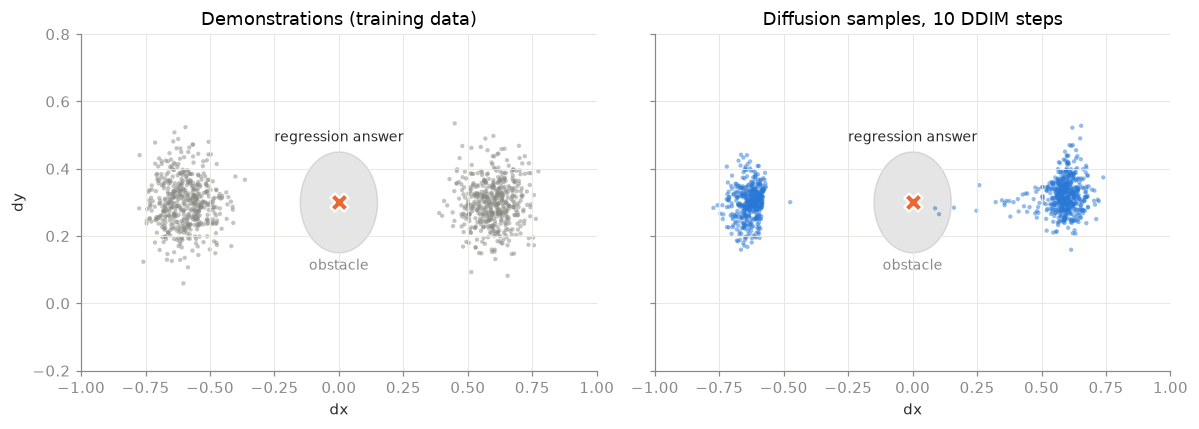

diffusion samples on a mode: 98.4%  (left 45%, right 55%)
regression answer on a mode: 0%


In [22]:
model.eval()
eps_fn = lambda x_t, t: model(x_t[:, 0], t)[:, None]                # sample() works on (B, H, A) = (B, 1, 2)
g = torch.Generator().manual_seed(0)
samples = cos_s.sample(eps_fn, (1000, 1, 2), num_inference_steps=10, generator=g)[:, 0]
data = sample_data(1000)

def on_mode(pts, radius=0.2):
    d = torch.cdist(pts, MODES).min(dim=1).values
    return (d < radius).float().mean().item()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
for ax, pts, title, c in [(axes[0], data, "Demonstrations (training data)", MUTED),
                          (axes[1], samples, "Diffusion samples, 10 DDIM steps", BLUE)]:
    ax.scatter(pts[:, 0], pts[:, 1], s=8, alpha=0.5, color=c, edgecolors="none")
    r = regressor.detach()
    ax.scatter([r[0]], [r[1]], s=140, color=ORANGE, marker="X", edgecolors="white", linewidths=1.5, zorder=3)
    ax.annotate("regression answer", (r[0], r[1]), xytext=(0, 40), textcoords="offset points", ha="center", color=INK, fontsize=9)
    ax.add_patch(plt.Circle((0, 0.3), 0.15, color=INK, alpha=0.12))
    ax.annotate("obstacle", (0, 0.1), ha="center", color=MUTED, fontsize=9)
    ax.set(title=title, xlabel="dx", xlim=(-1, 1), ylim=(-0.2, 0.8))
axes[0].set_ylabel("dy")
plt.tight_layout(); plt.show()
left = (samples[:, 0] < 0).float().mean().item()
print(f"diffusion samples on a mode: {on_mode(samples):.1%}  (left {left:.0%}, right {1 - left:.0%})")
print(f"regression answer on a mode: {on_mode(regressor.detach()[None]):.0%}")

The diffusion model reproduces both modes in roughly equal proportion; the regression model sits between them,
on the obstacle. Real demonstrations have the same property in subtler ways (pause or not, grasp a bit to the left
or right), which is the main argument of the Diffusion Policy paper.

## 6.2 How many DDIM steps, and does the spacing matter?

Same trained model, different numbers of sampling steps, our spacing vs the "leading" spacing from Part 4.
This is a preview of the DDIM-steps ablation in Step 14.

         ours (99 -> 0) leading (90 -> 0)
1 steps            0.0%              4.2%
2 steps            0.0%             40.3%
3 steps           86.0%             64.6%
5 steps           98.2%             84.7%
10 steps          98.2%             93.3%
20 steps          96.9%             96.0%
50 steps          96.2%             96.4%


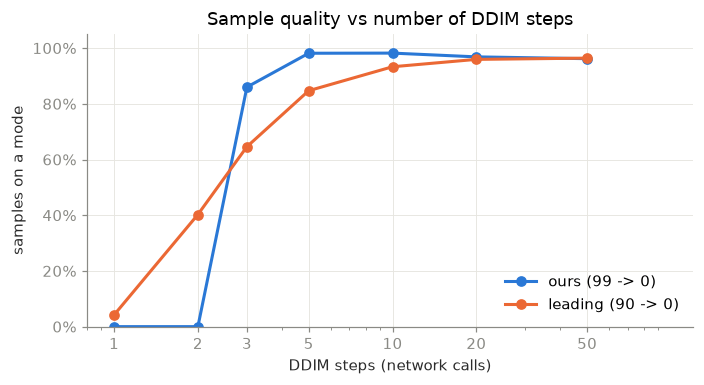

In [23]:
class LeadingScheduler(NoiseScheduler):
    # The common [90, 80, ..., 0] spacing, for comparison only.
    def ddim_timesteps(self, n):
        return [i * self.num_train_steps // n for i in range(n)][::-1]
lead_s = LeadingScheduler(100)

steps = [1, 2, 3, 5, 10, 20, 50]
res = {"ours (99 -> 0)": [], "leading (90 -> 0)": []}
for n in steps:
    for name, s in [("ours (99 -> 0)", cos_s), ("leading (90 -> 0)", lead_s)]:
        g = torch.Generator().manual_seed(0)
        pts = s.sample(eps_fn, (2000, 1, 2), num_inference_steps=n, generator=g)[:, 0]
        res[name].append(on_mode(pts))

print(pd.DataFrame(res, index=[f"{n} steps" for n in steps]).map(lambda v: f"{v:.1%}"))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for (name, vals), c in zip(res.items(), [BLUE, ORANGE]):
    ax.plot(steps, vals, color=c, marker="o", markersize=6, label=name)
ax.set_xscale("log"); ax.set_xticks(steps); ax.set_xticklabels(steps)
ax.set(xlabel="DDIM steps (network calls)", ylabel="samples on a mode", title="Sample quality vs number of DDIM steps",
       ylim=(0, 1.05), xlim=(0.8, 120))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

**Reading the result.** This is not quite what we predicted in Part 4, which is why we measure.

- **3 to 10 steps:** our spacing is better (86 % vs 65 % at 3 steps, 98 % vs 93 % at 10). Starting at k = 99 matches
  the pure noise we start from.
- **1 to 2 steps:** our spacing *fails* (0 %). Its first step is at k = 99, where the signal weight is
  √ᾱ = 0.0005, so the guess $\hat x_0 = (x_t - \sqrt{1-\bar\alpha}\,\hat\varepsilon)/0.0005$ multiplies every small error
  in $\hat\varepsilon$ by about 2000, and the clip pushes it to a corner of [−1, 1]². With only one or two steps there is no
  later step to fix it. (The leading spacing is also useless here: 4 % and 40 %.) The cure in the literature is to
  predict $x_0$ or a mix ("v-prediction") instead of ε; we keep ε-prediction, which is standard for Diffusion Policy.
- **20+ steps:** both spacings are equal; more steps cost more network calls for no gain.

Our default of **10 steps** is in the regime where our spacing is best. In the Step 14 ablation we test 3, 5, 10 and 20 steps, not 1–2.

## 6.3 Self-check

1. Why does the regression model predict (0, 0.3)?
2. In the real policy, what plays the role of the toy `ToyDenoiser`, and what extra input does it get?
3. Why are 10 DDIM steps a good default for robot control?
4. Why does a single DDIM step from k = 99 fail even though the model is well trained?

<details>
<summary>Answers</summary>

1. MSE is minimised by the mean of the targets, and the mean of two symmetric modes is the point between them.
2. The encoder–decoder Transformer: the decoder takes the 16 noisy action tokens and k (like the toy), and also
   cross-attends to the encoder's memory of the instruction, cameras and state. That makes it a *conditional* denoiser.
3. Quality has mostly saturated by 10 steps, while the cost grows linearly with steps. Every chunk must be produced
   fast enough to keep the robot moving (we measure ms per chunk in Step 16).
4. At k = 99 the clean chunk is weighted by √ᾱ = 0.0005, so recovering x̂₀ divides the network's small error in ε̂ by
   0.0005 (about ×2000). With several steps, later steps (at lower k, where this division is mild) correct the
   early bad guess; with one step that guess is the output.
</details>

---
## Summary

| Check | Result |
|---|---|
| ᾱ has shape (K,), lies in (0, 1), strictly decreasing | Part 1.3 |
| One-jump `add_noise` equals 100 small steps | Part 2.2 |
| `add_noise` matches the formula | Part 2.3 |
| ε-inversion is exact; "know-nothing" loss ≈ 1.0 | Part 3 |
| `ddim_step` matches the formula; oracle step is exact | Part 4.2 |
| Oracle `sample` recovers the real chunk (and gripper ±1) | Part 5.2 |
| A trained toy denoiser samples both modes; regression averages them | Part 6.1 |
| 10 DDIM steps are enough; our spacing beats "leading" at 3–10 steps, both fail at 1–2 | Part 6.2 |

How Step 8 will use the scheduler:

```python
# training (compute_loss)
k = torch.randint(0, K, (B,)); eps = torch.randn_like(actions)
loss = mse(decoder(scheduler.add_noise(actions, eps, k), k, memory), eps)

# inference (predict_action_chunk)
memory = encoder(observation)                                        # once
chunk = scheduler.sample(lambda x, k: decoder(x, k, memory), (B, 16, 7), num_inference_steps=10)
```

The official tests check the same file:

```bash
pytest tests/test_scheduler.py -v      # 4 passed
```

**Next: Step 6, the embedding cache.**